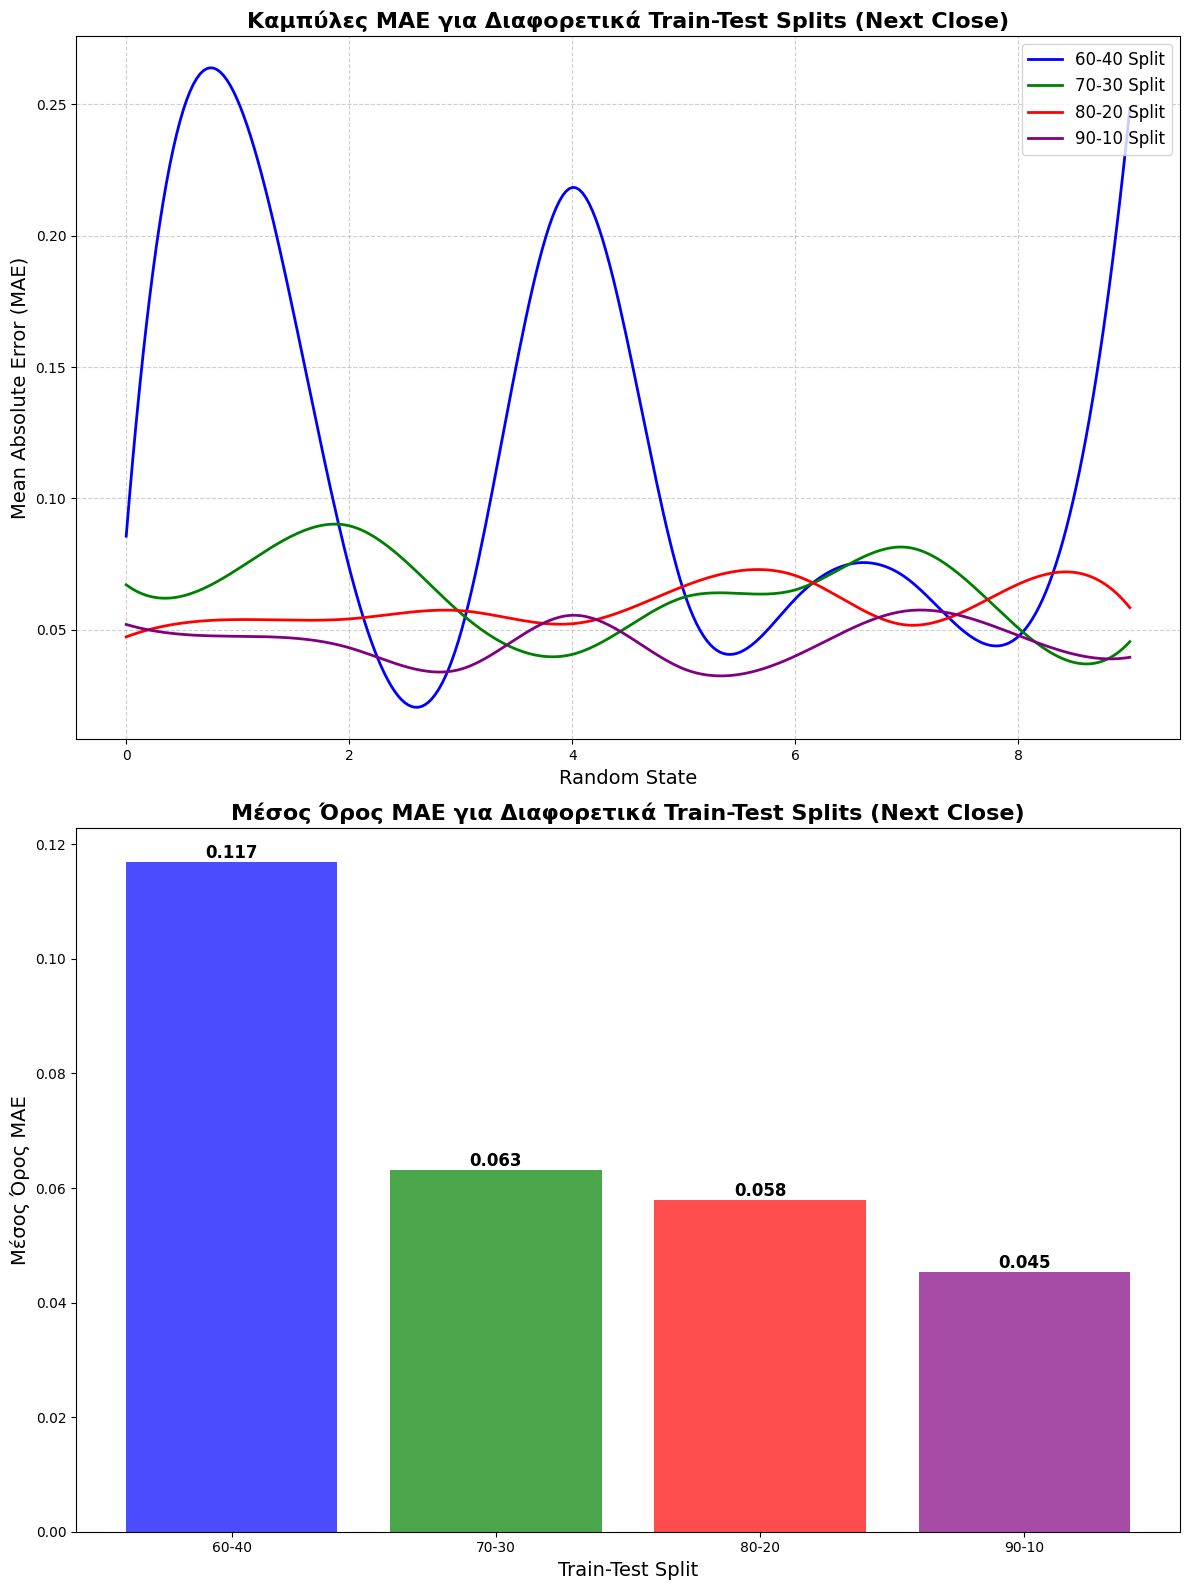

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.08561873900431395, 0.2514233073975079, 0.07362226267125656,
    0.04873536057155357, 0.21836857060885084, 0.06464025443627663,
    0.06172557358834387, 0.06957739896753014, 0.04740750497480459,
    0.24837173221233091
])
mae_70_30 = np.array([
    0.06709807255467276, 0.07306417087366285, 0.08956491025144941,
    0.05629435915169963, 0.04060869470801754, 0.06233378374909099,
    0.0651717988519046, 0.08136420497474646, 0.05062156532858227,
    0.04545472768609272
])
mae_80_20 = np.array([
    0.047278162047725836, 0.05385849549099754, 0.054109838169866864,
    0.057249893493925195, 0.0522660222635289, 0.06656732159232762,
    0.07063074505719559, 0.05178485158792499, 0.06734003719269174,
    0.05840206836764437
])
mae_90_10 = np.array([
    0.052005090727768724, 0.04749926260998544, 0.04313234594623305,
    0.034967183541954314, 0.055499171983046776, 0.03509261862647864,
    0.039972260035484736, 0.057192550114106275, 0.04778716660241618,
    0.03950186407094163
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)


axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Next Close)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Next Close)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()